**Dataset Information:**

The Student Performance Dataset is a dataset designed to examine the factors influencing academic student performance.
The dataset consists of **10,000** student records, with each record containing information about various predictors and a performance index.

Target variable will be the price.

In [ ]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge

In [ ]:
# load the data from csv
df = pd.read_csv('kc_house_data.csv')
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
# reframing the date format and setting the index
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('id')
df.price = df.price.astype(int)
df.bathrooms = df.bathrooms.astype(int)
df.floors = df.floors.astype(int)
df.head(5)

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
id,,,,,,,,,,,,,,,,,,,,
7129300520,2014-10-13,221900,3,1,1180,5650,1,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
6414100192,2014-12-09,538000,3,2,2570,7242,2,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
5631500400,2015-02-25,180000,2,1,770,10000,1,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
2487200875,2014-12-09,604000,4,3,1960,5000,1,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
1954400510,2015-02-18,510000,3,2,1680,8080,1,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
df["house_age"] = df["date"].dt.year - df['yr_built']
df['renovated'] = df['yr_renovated'].apply(lambda yr: 0 if yr == 0 else 1)

data=df.drop('date', axis=1)
data=data.drop('yr_renovated', axis=1)
data=data.drop('yr_built', axis=1)
data.head(5)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,house_age,renovated
id,,,,,,,,,,,,,,,,,,,
7129300520,221900,3,1,1180,5650,1,0,0,3,7,1180,0,98178,47.5112,-122.257,1340,5650,59,0
6414100192,538000,3,2,2570,7242,2,0,0,3,7,2170,400,98125,47.7210,-122.319,1690,7639,63,1
5631500400,180000,2,1,770,10000,1,0,0,3,6,770,0,98028,47.7379,-122.233,2720,8062,82,0
2487200875,604000,4,3,1960,5000,1,0,0,5,7,1050,910,98136,47.5208,-122.393,1360,5000,49,0
1954400510,510000,3,2,1680,8080,1,0,0,3,8,1680,0,98074,47.6168,-122.045,1800,7503,28,0


In [ ]:
pd.set_option('display.precision', 2)
print(data.describe())

          price  bedrooms  bathrooms  sqft_living  sqft_lot    floors  \
count  2.16e+04  21613.00   21613.00     21613.00  2.16e+04  21613.00   
mean   5.40e+05      3.37       1.75      2079.90  1.51e+04      1.45   
std    3.67e+05      0.93       0.73       918.44  4.14e+04      0.55   
min    7.50e+04      0.00       0.00       290.00  5.20e+02      1.00   
25%    3.22e+05      3.00       1.00      1427.00  5.04e+03      1.00   
50%    4.50e+05      3.00       2.00      1910.00  7.62e+03      1.00   
75%    6.45e+05      4.00       2.00      2550.00  1.07e+04      2.00   
max    7.70e+06     33.00       8.00     13540.00  1.65e+06      3.00   

       waterfront      view  condition     grade  sqft_above  sqft_basement  \
count    2.16e+04  21613.00   21613.00  21613.00    21613.00       21613.00   
mean     7.54e-03      0.23       3.41      7.66     1788.39         291.51   
std      8.65e-02      0.77       0.65      1.18      828.09         442.58   
min      0.00e+00      0.0

**Data Preprocessing**

In [ ]:
data.shape # Shape of the dataset

(21613, 19)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21613 entries, 7129300520 to 1523300157
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          21613 non-null  int64  
 1   bedrooms       21613 non-null  int64  
 2   bathrooms      21613 non-null  int64  
 3   sqft_living    21613 non-null  int64  
 4   sqft_lot       21613 non-null  int64  
 5   floors         21613 non-null  int64  
 6   waterfront     21613 non-null  int64  
 7   view           21613 non-null  int64  
 8   condition      21613 non-null  int64  
 9   grade          21613 non-null  int64  
 10  sqft_above     21613 non-null  int64  
 11  sqft_basement  21613 non-null  int64  
 12  zipcode        21613 non-null  int64  
 13  lat            21613 non-null  float64
 14  long           21613 non-null  float64
 15  sqft_living15  21613 non-null  int64  
 16  sqft_lot15     21613 non-null  int64  
 17  house_age      21613 non-null  int64  
 1

In [ ]:
data.describe() # get the insight of the statistics of dataset

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,house_age,renovated
count,2.16e+04,21613.00,21613.00,21613.00,2.16e+04,21613.00,2.16e+04,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00
mean,5.40e+05,3.37,1.75,2079.90,1.51e+04,1.45,7.54e-03,0.23,3.41,7.66,1788.39,291.51,98077.94,47.56,-122.21,1986.55,12768.46,43.32,0.04
std,3.67e+05,0.93,0.73,918.44,4.14e+04,0.55,8.65e-02,0.77,0.65,1.18,828.09,442.58,53.51,0.14,0.14,685.39,27304.18,29.38,0.20
min,7.50e+04,0.00,0.00,290.00,5.20e+02,1.00,0.00e+00,0.00,1.00,1.00,290.00,0.00,98001.00,47.16,-122.52,399.00,651.00,-1.00,0.00
25%,3.22e+05,3.00,1.00,1427.00,5.04e+03,1.00,0.00e+00,0.00,3.00,7.00,1190.00,0.00,98033.00,47.47,-122.33,1490.00,5100.00,18.00,0.00
50%,4.50e+05,3.00,2.00,1910.00,7.62e+03,1.00,0.00e+00,0.00,3.00,7.00,1560.00,0.00,98065.00,47.57,-122.23,1840.00,7620.00,40.00,0.00
75%,6.45e+05,4.00,2.00,2550.00,1.07e+04,2.00,0.00e+00,0.00,4.00,8.00,2210.00,560.00,98118.00,47.68,-122.12,2360.00,10083.00,63.00,0.00
max,7.70e+06,33.00,8.00,13540.00,1.65e+06,3.00,1.00e+00,4.00,5.00,13.00,9410.00,4820.00,98199.00,47.78,-121.31,6210.00,871200.00,115.00,1.00


In [ ]:
data.columns.tolist() # get the column names

['price',
 'bedrooms',
 'bathrooms',
 'sqft_living',
 'sqft_lot',
 'floors',
 'waterfront',
 'view',
 'condition',
 'grade',
 'sqft_above',
 'sqft_basement',
 'zipcode',
 'lat',
 'long',
 'sqft_living15',
 'sqft_lot15',
 'house_age',
 'renovated']

In [ ]:
data.isna().sum() # check for null value

,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0
condition,0
grade,0


In [ ]:
#checking duplicate values
data.nunique()

,0
price,4028
bedrooms,13
bathrooms,9
sqft_living,1038
sqft_lot,9782
floors,3
waterfront,2
view,5
condition,5
grade,12


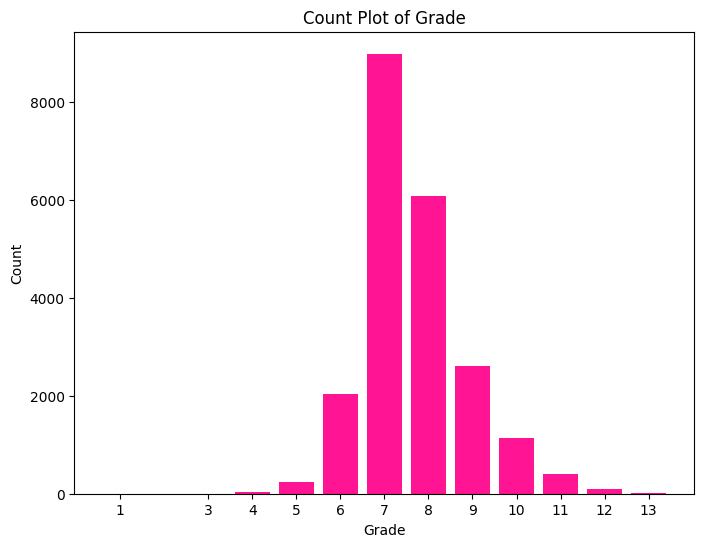

In [ ]:
# Calculate the value counts for the 'grade' column
quality_counts = df['grade'].value_counts()

# Using Matplotlib to create a count plot
plt.figure(figsize=(8, 6))
plt.bar(quality_counts.index, quality_counts, color='deeppink')
plt.title('Count Plot of Grade')
plt.xlabel('Grade')
plt.ylabel('Count')
plt.xticks(quality_counts.index)  # Ensure all grades appear on the x-axis
plt.show()

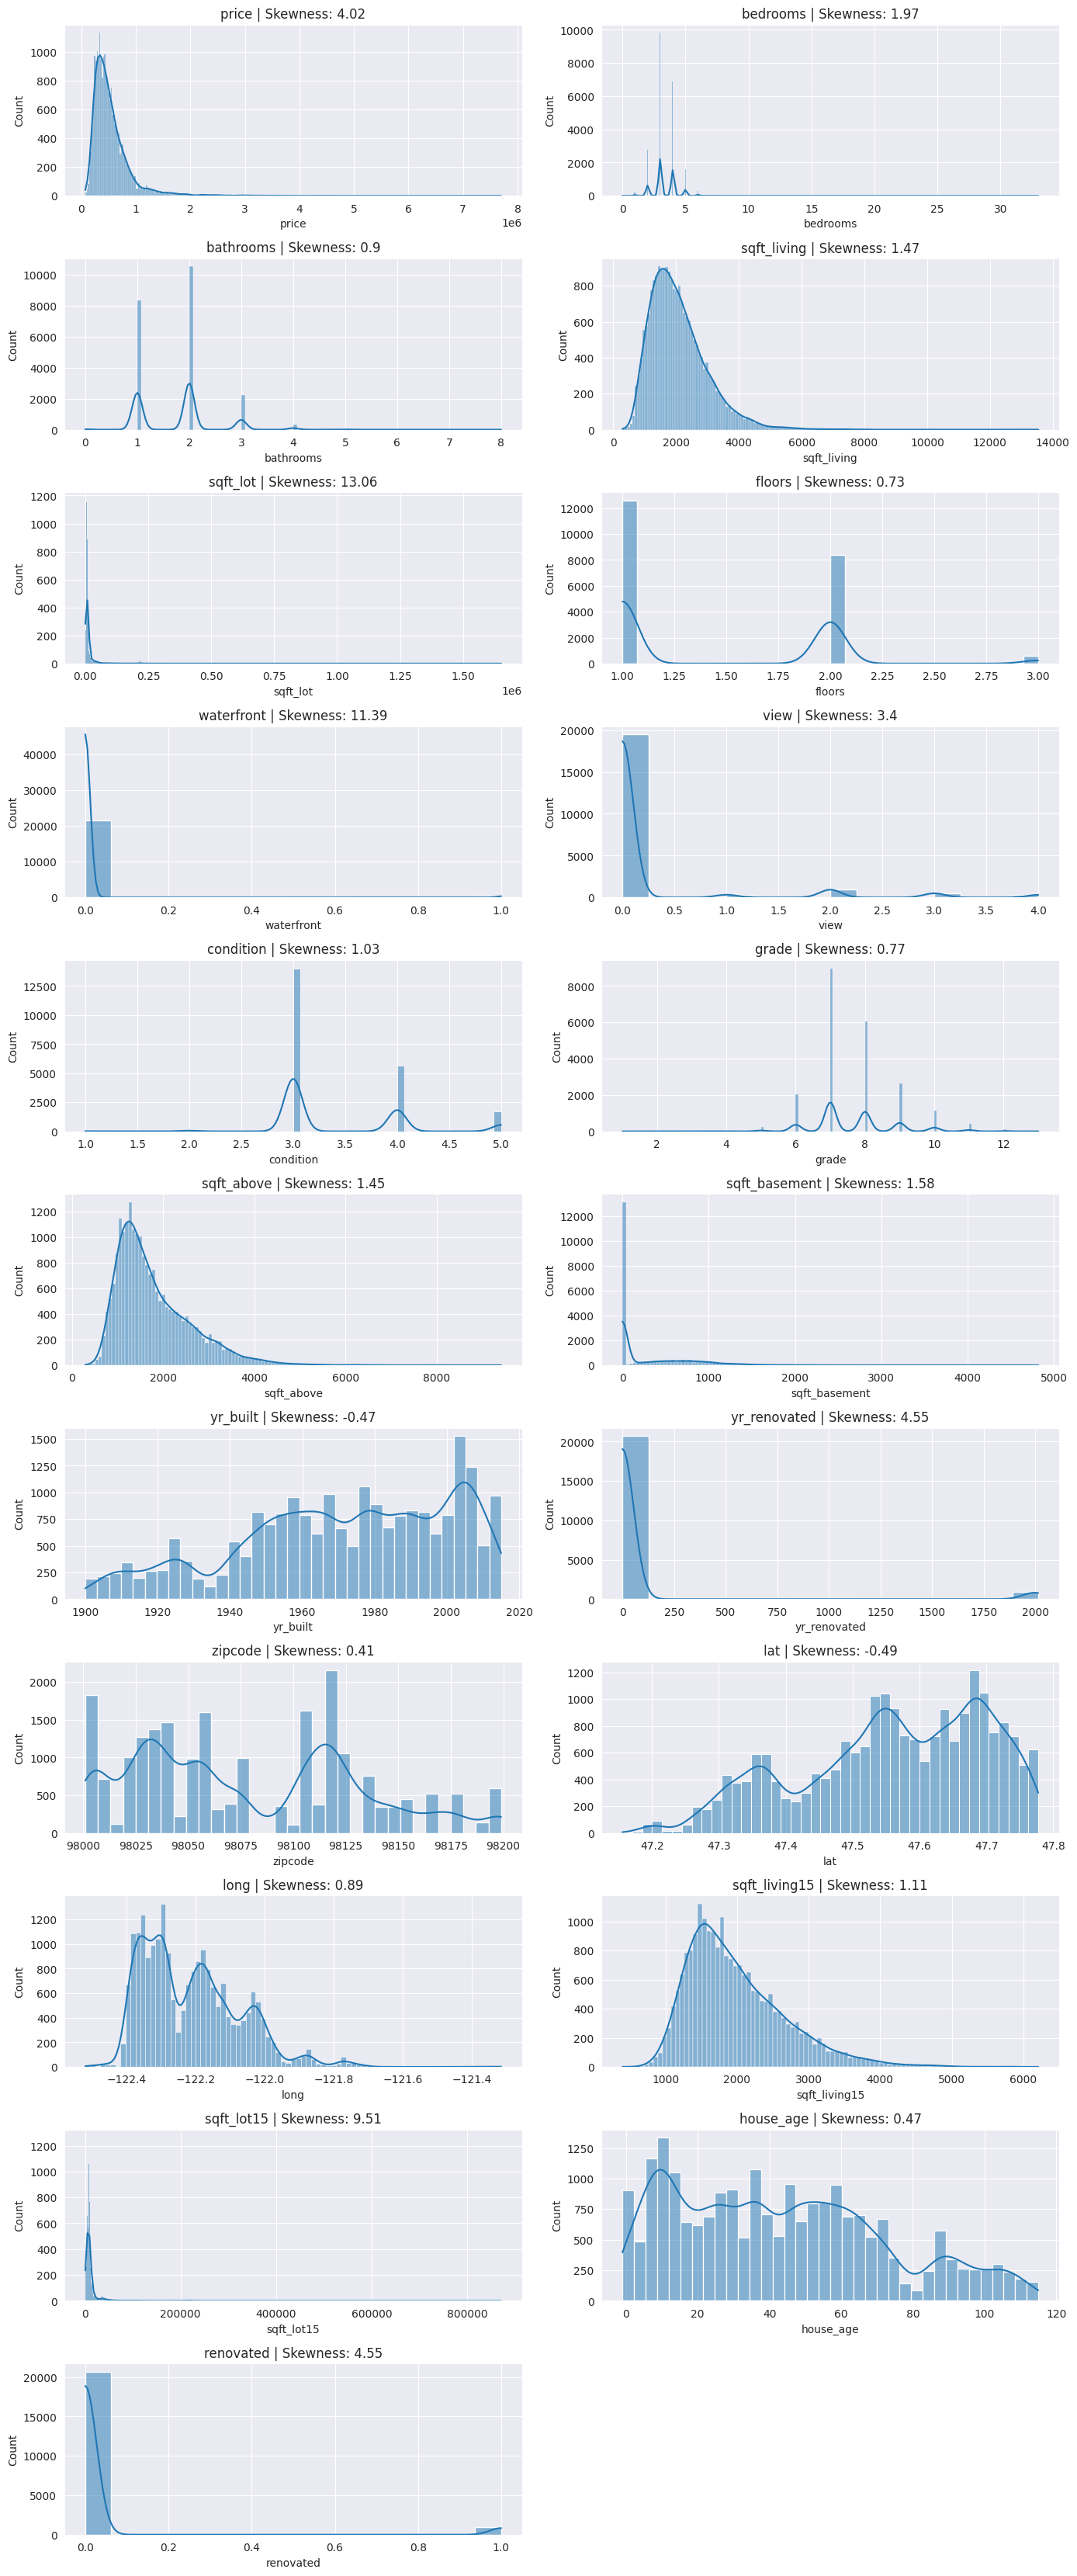

In [ ]:
# Set Seaborn style
sns.set_style("darkgrid")

# Identify numerical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

# Plot distribution of each numerical feature
plt.figure(figsize=(14, len(numerical_columns) * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns), 2, idx)
    sns.histplot(df[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")

# Adjust layout and show plots
plt.tight_layout()
plt.show()

<Axes: xlabel='grade', ylabel='price'>

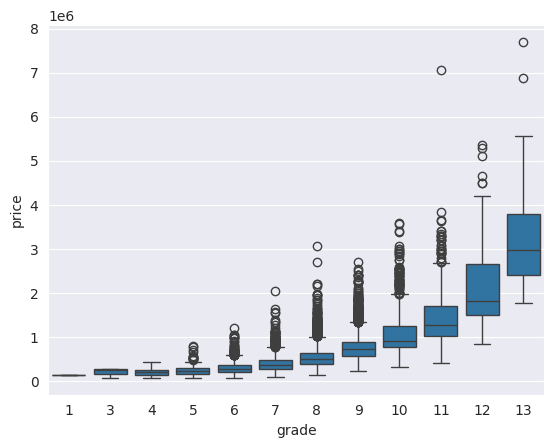

In [ ]:
#plotting box plot between alcohol and quality
sns.boxplot(x='grade', y='price', data=data)

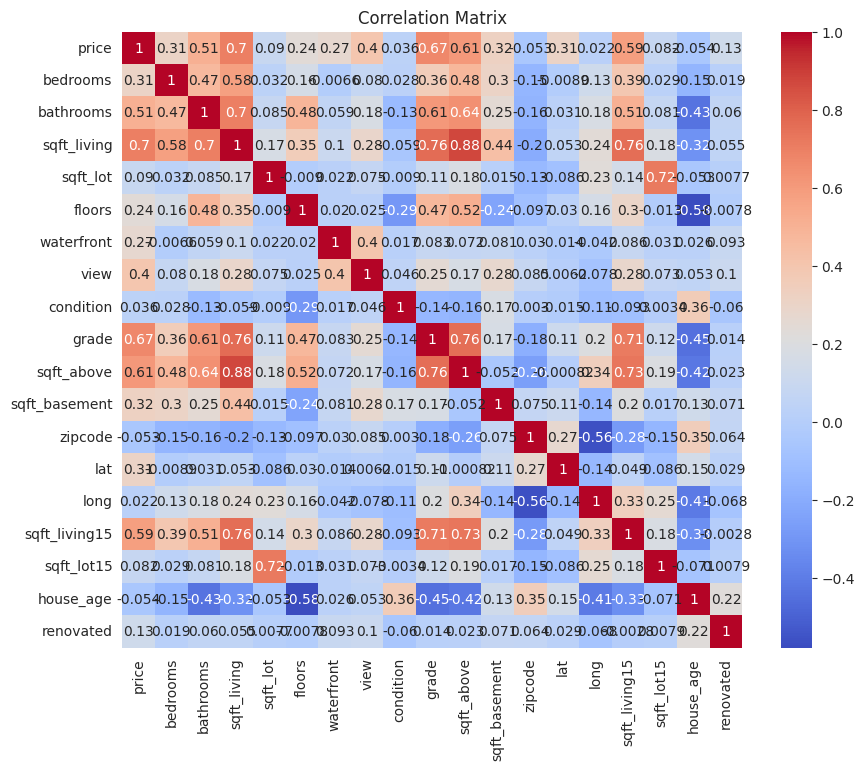

In [ ]:
# Calculate correlation matrix
correlation_matrix = data.corr()

# Plot heatmap of correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

# Assuming 'price' is your target variable
X = data.drop('price', axis=1)
y = data['price']

# Initialize estimator and RFE
estimator = LinearRegression()
selector = RFE(estimator, n_features_to_select=5)  # Select top 5 features

# Fit RFE
selector = selector.fit(X, y)

# Get selected features
selected_features = X.columns[selector.support_]
print(selected_features)

Index(['waterfront', 'grade', 'lat', 'long', 'renovated'], dtype='object')


In [ ]:
from sklearn.model_selection import train_test_split

# Assuming 'X' contains your selected features and 'y' is your target variable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # Adjust test_size and random_state as needed

In [ ]:
X_train

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,house_age,renovated
id,,,,,,,,,,,,,,,,,,
5467910190,3,1,1780,13095,1,0,0,4,9,1780,0,98042,47.37,-122.15,2750,13095,31,0
9331800580,2,1,1000,3700,1,0,0,3,6,800,200,98118,47.55,-122.29,1270,5000,86,0
2407000405,3,1,1080,7486,1,0,0,3,6,990,90,98146,47.48,-122.33,1170,7800,73,0
5466700290,3,2,2090,7500,1,0,0,4,7,1280,810,98031,47.40,-122.17,1800,7350,38,0
3026059361,2,2,1741,1439,2,0,0,3,8,1446,295,98034,47.70,-122.21,2090,10454,8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5272200045,3,1,1000,6914,1,0,0,3,7,1000,0,98125,47.71,-122.32,1000,6947,67,0
9578500790,3,2,3087,5002,2,0,0,3,8,3087,0,98023,47.30,-122.35,2927,5183,0,0
7202350480,3,2,2120,4780,2,0,0,3,7,2120,0,98053,47.68,-122.03,1690,2650,10,0


In [ ]:
y_train

,price
id,
5467910190,325000
9331800580,257000
2407000405,228500
5466700290,288000
3026059361,479000
...,...
5272200045,378000
9578500790,399950
7202350480,575000


In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((17290, 18), (4323, 18), (17290,), (4323,))

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
import numpy as np
y_pred = model.predict(X_test)

# Evaluate the model
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2)

Mean Squared Error: 44995553665.04825
Root Mean Squared Error: 212121.55398508717
R-squared: 0.7023645177003279


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest Regressor
rf_model = RandomForestRegressor(random_state=42)  # Adjust random_state as needed

# Fit the model
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest - Mean Squared Error:", mse_rf)
print("Random Forest - Root Mean Squared Error:", rmse_rf)
print("Random Forest - R-squared:", r2_rf)

Random Forest - Mean Squared Error: 22044093726.529617
Random Forest - Root Mean Squared Error: 148472.53525999218
Random Forest - R-squared: 0.8541832707072262


In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Initialize Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)  # Adjust random_state as needed

# Fit the model
dt_model.fit(X_train, y_train)


DecisionTreeRegressor(random_state=42)

In [ ]:
# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_rf = np.sqrt(mse_dt)
r2_rf = r2_score(y_test, y_pred_dt)

print("Decision Tree - Mean Squared Error:", mse_rf)
print("Decision Tree - Root Mean Squared Error:", rmse_rf)
print("Decision Tree - R-squared:", r2_rf)

Decision Tree - Mean Squared Error: 22044093726.529617
Decision Tree - Root Mean Squared Error: 201211.27550629462
Decision Tree - R-squared: 0.7321943519840387


In [ ]:
# Initialize Ridge Regression model
ridge_model = Ridge(alpha=1.0)  # Adjust alpha (regularization strength) as needed

# Fit the model
ridge_model.fit(X_train, y_train)

Ridge()

In [ ]:
# Make predictions
y_pred_ridge = ridge_model.predict(X_test)

# Evaluate the model
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression - Mean Squared Error:", mse_ridge)
print("Ridge Regression - Root Mean Squared Error:", rmse_ridge)
print("Ridge Regression - R-squared:", r2_ridge)

Ridge Regression - Mean Squared Error: 45007450393.392075
Ridge Regression - Root Mean Squared Error: 212149.59437479978
Ridge Regression - R-squared: 0.7022858235141254


In [ ]:
# Initialize Lasso Regression model
lasso_model = Lasso(alpha=1.0)  # Adjust alpha (regularization strength) as needed

# Fit the model
lasso_model.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.058e+14, tolerance: 2.259e+11
  model = cd_fast.enet_coordinate_descent(


Lasso()

In [ ]:
# Make predictions
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate the model
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression - Mean Squared Error:", mse_lasso)
print("Lasso Regression - Root Mean Squared Error:", rmse_lasso)
print("Lasso Regression - R-squared:", r2_lasso)

Lasso Regression - Mean Squared Error: 44996034191.17299
Lasso Regression - Root Mean Squared Error: 212122.68664896028
Lasso Regression - R-squared: 0.7023613391279304


**Best Fit Model is Random Forest Which gives 85.41% accuracy.**

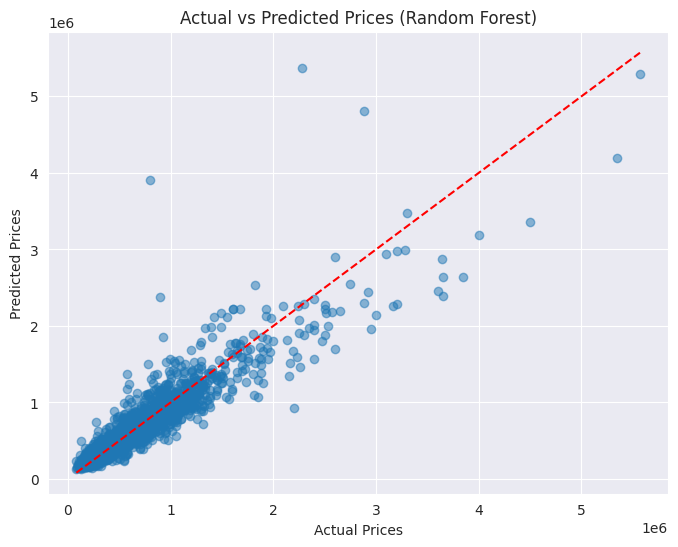

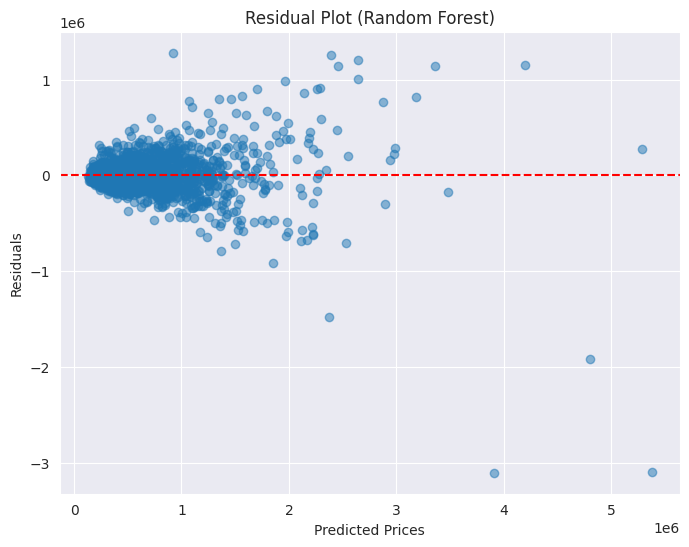

In [ ]:
# Scatter plot of actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.5)  # Use y_pred_rf for Random Forest predictions
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle='--', color='red')
plt.title("Actual vs Predicted Prices (Random Forest)")
plt.show()

# Residual plot
residuals = y_test - y_pred_rf  # Use y_pred_rf for Random Forest residuals
plt.figure(figsize=(8, 6))
plt.scatter(y_pred_rf, residuals, alpha=0.5)
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot (Random Forest)")
plt.axhline(y=0, color='r', linestyle='--')  # Add a horizontal line at zero
plt.show()